# Giai đoạn 5b: Mô hình Deep Learning — TextCNN (Multi-scale 1D CNN trên Word Embedding)

Huấn luyện và đánh giá **`TN5_textcnn` (`TextCNNClassifier`)** trên bộ dữ liệu **22 nhãn chuẩn** (`18.603` mẫu `webtruyen.vn`; `train=13.297`, `val=2.634`, `test=2.672`).

### Kiến trúc & tối ưu cho bài toán phân loại thể loại truyện:
1. **N-gram CNN đa tỷ lệ (`kernel_sizes = (2, 3, 4)`):** Các bộ lọc 1D Conv bắt trực tiếp cụm từ khóa 2–4 token đặc trưng thể loại (tương đương vai trò $n$-gram của TF-IDF nhưng học được biểu diễn ngữ nghĩa phân tán).
2. **Khởi tạo Pretrained Embedding (`PPMI + TruncatedSVD`, `128` chiều):** Học trực tiếp từ tập `train` (`vocab = 20.000`, `max_len = 200`), không gây rò rỉ dữ liệu `val/test`.
3. **Global Max + Masked Mean Pooling & Regularization:** Giữ được cả tín hiệu từ khóa sắc bén nhất lẫn ngữ cảnh toàn đoạn tóm tắt; sử dụng `SpatialDropout(0.15)`, `BatchNorm1d`, `GELU`, `sqrt pos_weight (max=3.5)` và `OneCycleLR`.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, TensorDataset

from src.config import (
    EXPERIMENTS_CSV,
    FIGURES_DIR,
    GENRE_DISPLAY_NAMES,
    GENRE_LABELS,
    MODELS_DIR,
    RANDOM_STATE,
    STORIES_CLEAN_CSV,
)
from src.evaluation.metrics import (
    evaluate_model,
    plot_dl_learning_curves,
    plot_f1_per_label,
    plot_model_comparison,
    save_experiment_result,
)
from src.features.embedding import (
    build_corpus_embeddings,
    build_vocab,
    texts_to_sequences,
)
from src.models.ml_models import apply_thresholds, tune_per_label_thresholds
from src.models.textcnn import (
    TextCNNClassifier,
    compute_pos_weights,
    predict_torch_probs,
    save_textcnn_checkpoint,
    train_torch_multilabel,
)

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(max(4, os.cpu_count() or 4))
print(f"PyTorch: {torch.__version__} | Thiết bị: {device} | CPU threads: {torch.get_num_threads()}")

df = pd.read_csv(STORIES_CLEAN_CSV, encoding="utf-8")
label_cols = [f"label_{g}" for g in GENRE_LABELS]
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

y_train = train_df[label_cols].to_numpy(dtype=np.float32)
y_val = val_df[label_cols].to_numpy(dtype=np.float32)
y_test = test_df[label_cols].to_numpy(dtype=np.float32)

MAX_LEN = 200
EMB_DIM = 128
BATCH_SIZE = 256

train_tokens = train_df["tokens"].fillna("")
val_tokens = val_df["tokens"].fillna("")
test_tokens = test_df["tokens"].fillna("")

vocab = build_vocab(train_tokens, min_freq=2, max_vocab_size=20000)
x_seq_train = texts_to_sequences(train_tokens, vocab, max_len=MAX_LEN)
x_seq_val = texts_to_sequences(val_tokens, vocab, max_len=MAX_LEN)
x_seq_test = texts_to_sequences(test_tokens, vocab, max_len=MAX_LEN)

t_emb = time.perf_counter()
pretrained_matrix = build_corpus_embeddings(
    train_tokens,
    vocab,
    embedding_dim=EMB_DIM,
    window=4,
    min_cooccur=2,
    n_iter=3,
    scale=0.5,
)
emb_time = time.perf_counter() - t_emb

pin_mem = device == "cuda"
seq_train_loader = DataLoader(
    TensorDataset(torch.tensor(x_seq_train, dtype=torch.long), torch.tensor(y_train)),
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=pin_mem,
)
seq_val_loader = DataLoader(
    TensorDataset(torch.tensor(x_seq_val, dtype=torch.long), torch.tensor(y_val)),
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=pin_mem,
)
seq_test_loader = DataLoader(
    TensorDataset(torch.tensor(x_seq_test, dtype=torch.long), torch.tensor(y_test)),
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=pin_mem,
)

pos_weight = compute_pos_weights(y_train, max_weight=3.5, mode="sqrt")
THRESH_GRID = np.round(np.linspace(0.15, 0.85, 71), 2)

print(f"Tập dữ liệu: train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")
print(
    f"Vocab TextCNN (min_freq=2): {len(vocab)} | Seq shape: {x_seq_train.shape} | "
    f"PPMI-SVD Embedding: {pretrained_matrix.shape} ({emb_time:.2f}s)"
)
print("pos_weight (sqrt, max=3.5):", {lbl: round(float(w), 2) for lbl, w in zip(GENRE_LABELS, pos_weight)})

PyTorch: 2.8.0+cpu | Thiết bị: cpu | CPU threads: 4


Tập dữ liệu: train=13297, val=2634, test=2672
Vocab TextCNN (min_freq=2): 20002 | Seq shape: (13297, 200) | PPMI-SVD Embedding: (20002, 128) (2.24s)
pos_weight (sqrt, max=3.5): {'ngon_tinh': 1.18, 'dam_my': 1.96, 'bach_hop': 3.5, 'tien_hiep': 3.5, 'kiem_hiep': 3.5, 'huyen_huyen': 3.01, 'linh_di': 3.5, 'khoa_huyen_mat_the': 3.5, 'vong_du': 3.5, 'trinh_tham': 3.5, 'dien_van': 3.5, 'lich_su_quan_su': 3.5, 'co_dai': 1.5, 'hien_dai': 1.54, 'cung_dau_gia_dau': 3.04, 'xuyen_khong': 2.7, 'trong_sinh': 2.81, 'he_thong': 3.5, 'nu_cuong': 2.07, 'sung': 1.78, 'nguoc': 3.4, 'hai_huoc': 2.93}


### Chuẩn bị dữ liệu & Khởi tạo Embedding cho TextCNN
- Nạp tập chia `13.297 / 2.634 / 2.672`, xây dựng từ điển `20.002` token (`min_freq=2`, tối đa `20.000`), chuẩn hóa độ dài chuỗi `max_len=200`, khởi tạo ma trận Word Embedding `128` chiều bằng `PPMI + TruncatedSVD` trên `train` và tính `pos_weight` (`sqrt`, `max_weight=3.5`).

In [2]:
# Huấn luyện TN5: TextCNN (Multi-scale Conv1d + Global Max & Masked Mean Pooling)
NUM_FILTERS = 64
KERNEL_SIZES = (2, 3, 4)
DROPOUT = 0.35
SPATIAL_DROPOUT = 0.15

t0 = time.perf_counter()
textcnn_model = TextCNNClassifier(
    vocab_size=len(vocab),
    num_classes=len(GENRE_LABELS),
    embedding_dim=EMB_DIM,
    num_filters=NUM_FILTERS,
    kernel_sizes=KERNEL_SIZES,
    dropout=DROPOUT,
    pretrained_embeddings=pretrained_matrix,
    freeze_embeddings=False,
    spatial_dropout=SPATIAL_DROPOUT,
)
textcnn_model, cnn_history = train_torch_multilabel(
    textcnn_model,
    train_loader=seq_train_loader,
    val_loader=seq_val_loader,
    y_val=y_val.astype(int),
    epochs=10 if len(train_df) > 5000 else 20,
    lr=3e-3,
    weight_decay=1e-4,
    pos_weight=pos_weight,
    patience=4,
    device=device,
    use_scheduler=True,
    scheduler_type="onecycle",
    use_amp=True,
)
cnn_train_s = time.perf_counter() - t0

cnn_val_probs = predict_torch_probs(textcnn_model, seq_val_loader, device=device)
cnn_val_default = evaluate_model(
    y_val.astype(int),
    apply_thresholds(cnn_val_probs, 0.5),
    label_names=GENRE_LABELS,
)
cnn_opt_thresh = tune_per_label_thresholds(y_val.astype(int), cnn_val_probs, grid=THRESH_GRID)
cnn_val_tuned = evaluate_model(
    y_val.astype(int),
    apply_thresholds(cnn_val_probs, cnn_opt_thresh),
    label_names=GENRE_LABELS,
)

use_tuned = cnn_val_tuned["macro_f1"] >= cnn_val_default["macro_f1"]
chosen_thresh = cnn_opt_thresh if use_tuned else np.full(len(GENRE_LABELS), 0.5, dtype=np.float32)

save_textcnn_checkpoint(
    textcnn_model,
    vocab=vocab,
    max_len=MAX_LEN,
    thresholds=chosen_thresh,
    path=MODELS_DIR / "textcnn.pt",
)

print(f"[TN5 TextCNN] Thời gian train: {cnn_train_s:.2f}s | Số epoch đã chạy: {len(cnn_history['train_loss'])}")
print(
    f"  Val (ngưỡng 0.5)    : Accuracy={cnn_val_default['accuracy']}, "
    f"Macro-F1={cnn_val_default['macro_f1']}, Micro-F1={cnn_val_default['micro_f1']}, Hamming={cnn_val_default['hamming_loss']}"
)
print(
    f"  Val (ngưỡng tối ưu) : Accuracy={cnn_val_tuned['accuracy']}, "
    f"Macro-F1={cnn_val_tuned['macro_f1']}, Micro-F1={cnn_val_tuned['micro_f1']}, Hamming={cnn_val_tuned['hamming_loss']}"
)
display(pd.DataFrame(cnn_history).assign(epoch=lambda d: np.arange(1, len(d) + 1)))

[TN5 TextCNN] Thời gian train: 284.83s | Số epoch đã chạy: 10
  Val (ngưỡng 0.5)    : Accuracy=0.0835, Macro-F1=0.4194, Micro-F1=0.5728, Hamming=0.1146
  Val (ngưỡng tối ưu) : Accuracy=0.0494, Macro-F1=0.4505, Micro-F1=0.5918, Hamming=0.134


,train_loss,val_loss,val_macro_f1,val_micro_f1,epoch
0,0.6993,0.6406,0.0621,0.3202,1
1,0.4531,0.4432,0.2881,0.5458,2
2,0.3923,0.4228,0.3363,0.5815,3
3,0.3508,0.4188,0.3785,0.5831,4
4,0.3137,0.4312,0.3883,0.5878,5
5,0.2802,0.4431,0.4041,0.5703,6
6,0.2507,0.4504,0.4073,0.5773,7
7,0.2303,0.4592,0.4104,0.5740,8
8,0.2181,0.4624,0.4194,0.5728,9
9,0.2152,0.4633,0.4182,0.5721,10


### Phân tích quá trình huấn luyện `TN5_textcnn`
- `TextCNNClassifier` (`k=2,3,4`, `num_filters=64`, `emb=128 PPMI-SVD`) chạy `10 epochs` trong `284.83s` (đỉnh epoch `9`: `val_macro_f1 = 0.4194`, `val_micro_f1 = 0.5728`, `Accuracy = 0.0835` ở ngưỡng `0.5`); sau tối ưu ngưỡng 71 điểm trên `val` đạt `val_macro_f1 = 0.4505`, `val_micro_f1 = 0.5918`.

In [3]:
# Đánh giá cuối cùng trên tập TEST (chạy duy nhất 1 lần) & cập nhật experiments.csv
if EXPERIMENTS_CSV.exists() and EXPERIMENTS_CSV.stat().st_size > 0:
    exp_existing = pd.read_csv(EXPERIMENTS_CSV, encoding="utf-8")
    if "experiment_id" in exp_existing.columns:
        valid_exp_ids = [
            "TN1_nb_bow",
            "TN2_multinomial_nb",
            "TN3_linear_svm",
            "TN4_logistic_regression",
            "TN5_textcnn",
        ]
        exp_existing = exp_existing[exp_existing["experiment_id"].isin(valid_exp_ids)]
        exp_existing.to_csv(EXPERIMENTS_CSV, index=False, encoding="utf-8")

t0 = time.perf_counter()
te_probs = predict_torch_probs(textcnn_model, seq_test_loader, device=device)
infer_ms = (time.perf_counter() - t0) * 1000.0

thresh_mode = "tuned_thresholds" if use_tuned else "threshold=0.5"
te_preds = apply_thresholds(te_probs, thresholds=chosen_thresh, ensure_non_empty=True)
te_metrics = evaluate_model(y_test.astype(int), te_preds, label_names=GENRE_LABELS)

dl_thresholds_json = {
    "TN5_textcnn": {lbl: round(float(chosen_thresh[i]), 2) for i, lbl in enumerate(GENRE_LABELS)}
}
(MODELS_DIR / "dl_thresholds.json").write_text(
    json.dumps(dl_thresholds_json, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

save_experiment_result(
    experiment_id="TN5_textcnn",
    model_name="TextCNN (Word Embedding)",
    feature_type=f"PPMI-SVD Emb + Multi-scale CNN (max_len={MAX_LEN})",
    metrics=te_metrics,
    notes=f"Test set ({len(y_test)} mẫu) | TextCNN (k=2,3,4; f={NUM_FILTERS}; emb={EMB_DIM} PPMI-SVD) + sqrt pos_weight | {thresh_mode}",
    output_path=EXPERIMENTS_CSV,
)

all_exp_df = pd.read_csv(EXPERIMENTS_CSV, encoding="utf-8")
print("=== BẢNG TỔNG HỢP TOÀN BỘ 5 THÍ NGHIỆM (ML vs TEXTCNN) TRÊN TẬP TEST ===")
display(all_exp_df)

print(
    f"\nMô hình Deep Learning TextCNN: Accuracy={te_metrics['accuracy']}, "
    f"Macro-F1={te_metrics['macro_f1']}, Micro-F1={te_metrics['micro_f1']}, "
    f"Hamming={te_metrics['hamming_loss']}, infer={infer_ms:.2f} ms"
)

dl_per_label_rows = []
for lbl in GENRE_LABELS:
    row = te_metrics["per_label"][lbl]
    dl_per_label_rows.append(
        {
            "label": lbl,
            "ten_hien_thi": GENRE_DISPLAY_NAMES.get(lbl, lbl),
            "precision": round(row["precision"], 4),
            "recall": round(row["recall"], 4),
            "f1_score": round(row["f1-score"], 4),
            "support": int(row["support"]),
        }
    )
dl_per_label_df = pd.DataFrame(dl_per_label_rows).sort_values("f1_score", ascending=False).reset_index(drop=True)
display(dl_per_label_df)

=== BẢNG TỔNG HỢP TOÀN BỘ 5 THÍ NGHIỆM (ML vs TEXTCNN) TRÊN TẬP TEST ===


,experiment_id,model_name,feature_type,accuracy,macro_f1,micro_f1,hamming_loss,notes
0,TN1_nb_bow,Multinomial NB (BoW),BoW (1-2 gram),0.0603,0.4319,0.5641,0.1300,Test set (2672 mẫu) | alpha=0.1 | tuned_thresh...
1,TN2_multinomial_nb,Multinomial NB (TF-IDF),TF-IDF (1-2 gram),0.0584,0.4031,0.5877,0.1207,Test set (2672 mẫu) | alpha=0.05 | tuned_thres...
2,TN3_linear_svm,Linear SVM (TF-IDF),TF-IDF (1-2 gram),0.0618,0.4767,0.6006,0.1193,"Test set (2672 mẫu) | C=0.25, cw=balanced | tu..."
3,TN4_logistic_regression,Logistic Regression (TF-IDF),TF-IDF (1-2 gram),0.0561,0.4897,0.6035,0.1230,"Test set (2672 mẫu) | C=1.0, cw=balanced | tun..."
4,TN5_textcnn,TextCNN (Word Embedding),PPMI-SVD Emb + Multi-scale CNN (max_len=200),0.0423,0.4381,0.5742,0.1383,"Test set (2672 mẫu) | TextCNN (k=2,3,4; f=64; ..."



Mô hình Deep Learning TextCNN: Accuracy=0.0423, Macro-F1=0.4381, Micro-F1=0.5742, Hamming=0.1383, infer=1694.25 ms


,label,ten_hien_thi,precision,recall,f1_score,support
0,ngon_tinh,Ngôn tình (Nam–Nữ),0.7575,0.9334,0.8363,1576
1,co_dai,Cổ đại,0.7961,0.8480,0.8213,875
2,dam_my,Đam mỹ,0.7404,0.7857,0.7624,588
3,hien_dai,Hiện đại / Đô thị,0.5575,0.8230,0.6647,842
4,tien_hiep,Tiên hiệp,0.6648,0.6393,0.6518,183
5,huyen_huyen,Huyền huyễn / Dị giới,0.4358,0.5739,0.4954,284
6,xuyen_khong,Xuyên không / Xuyên nhanh,0.4660,0.5159,0.4897,345
7,nu_cuong,Nữ cường,0.3800,0.6713,0.4853,505
8,sung,Sủng / Ngọt,0.3054,0.7928,0.4409,666
9,kiem_hiep,Kiếm hiệp,0.3676,0.5208,0.4310,48


### Phân tích so sánh TextCNN vs ML Baselines trên tập Test (`2.672` mẫu)
- **`TN5_textcnn`** đạt **`Macro-F1 = 0.4381`**, **`Micro-F1 = 0.5742`**, `Accuracy = 0.0423`, `Hamming Loss = 0.1383` (`infer = 1694.25 ms`), nổi bật trên các thể loại giàu cụm từ khóa như `ngon_tinh` (`0.8363`), `co_dai` (`0.8213`), `dam_my` (`0.7624`), `hien_dai` (`0.6647`), `tien_hiep` (`0.6518`). **`TN4_logistic_regression`** dẫn đầu chung cuộc ở `Macro-F1` (`0.4897`) và `Micro-F1` (`0.6035`).

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\dl_learning_curves.png


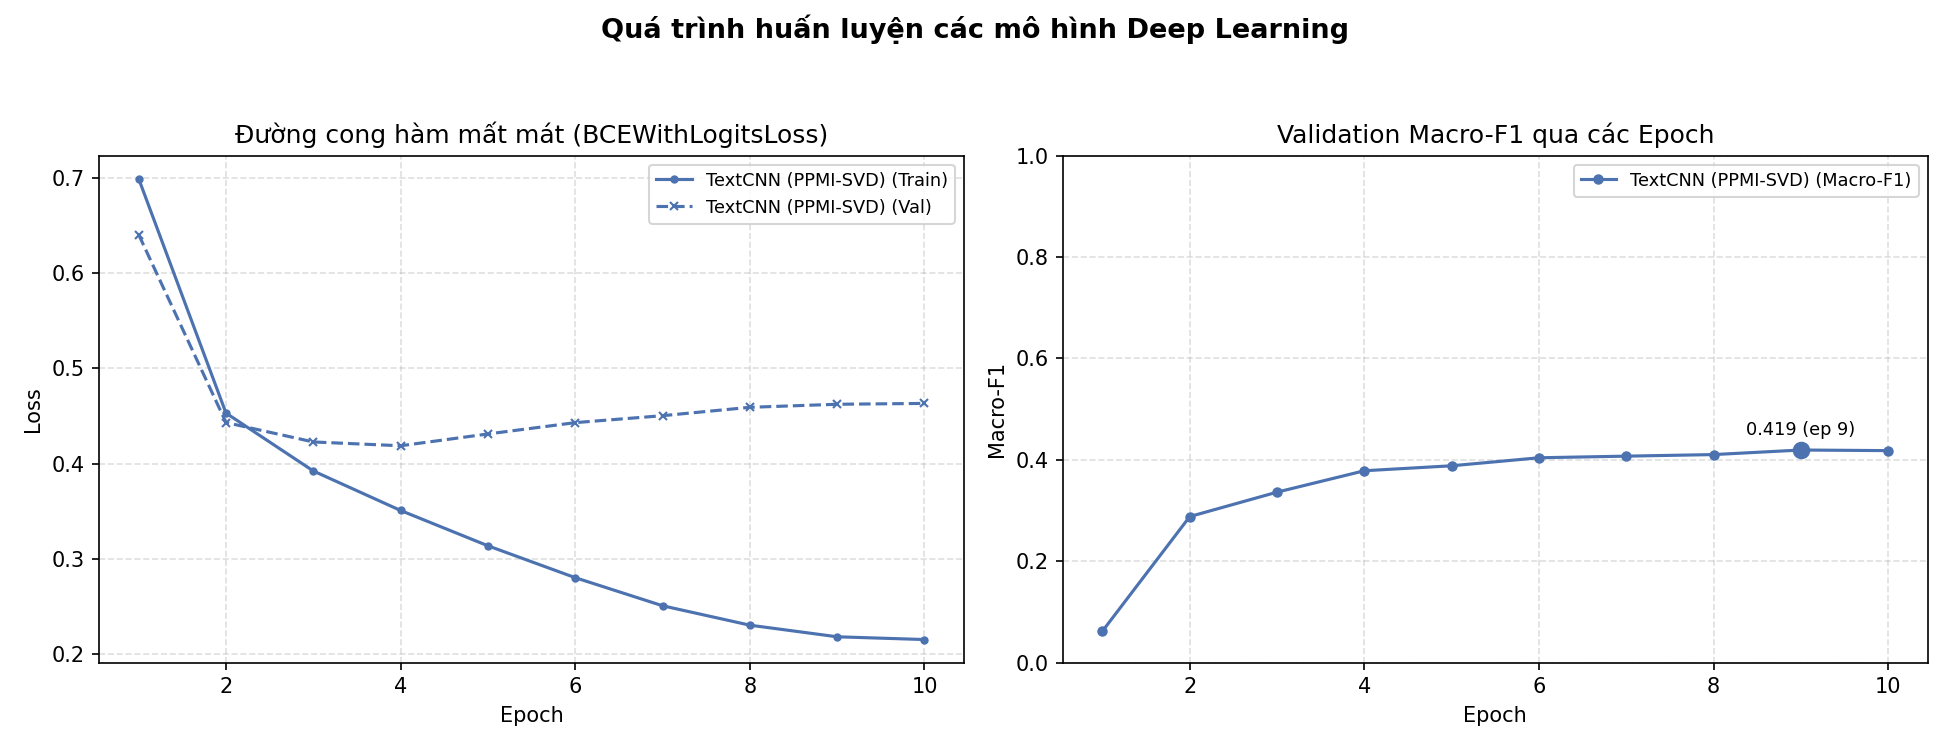

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\all_models_comparison.png


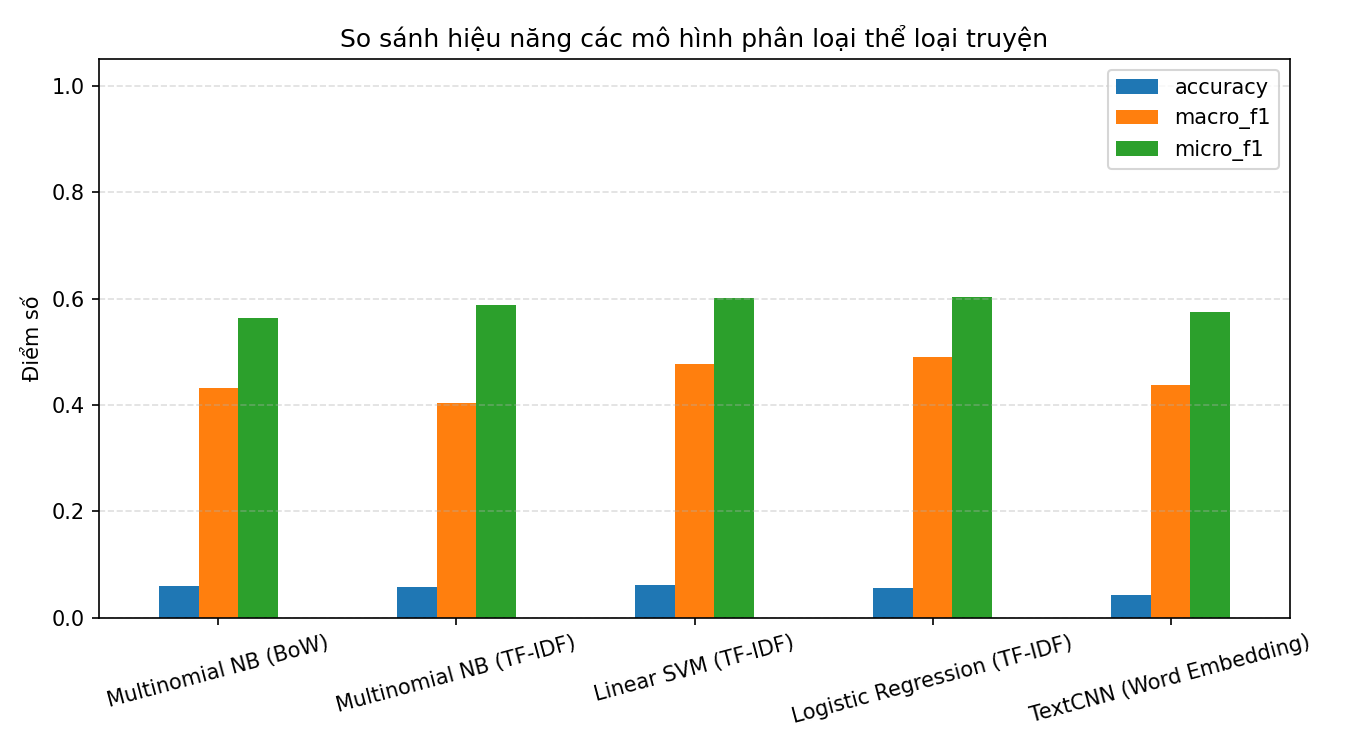

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\dl_f1_per_label.png


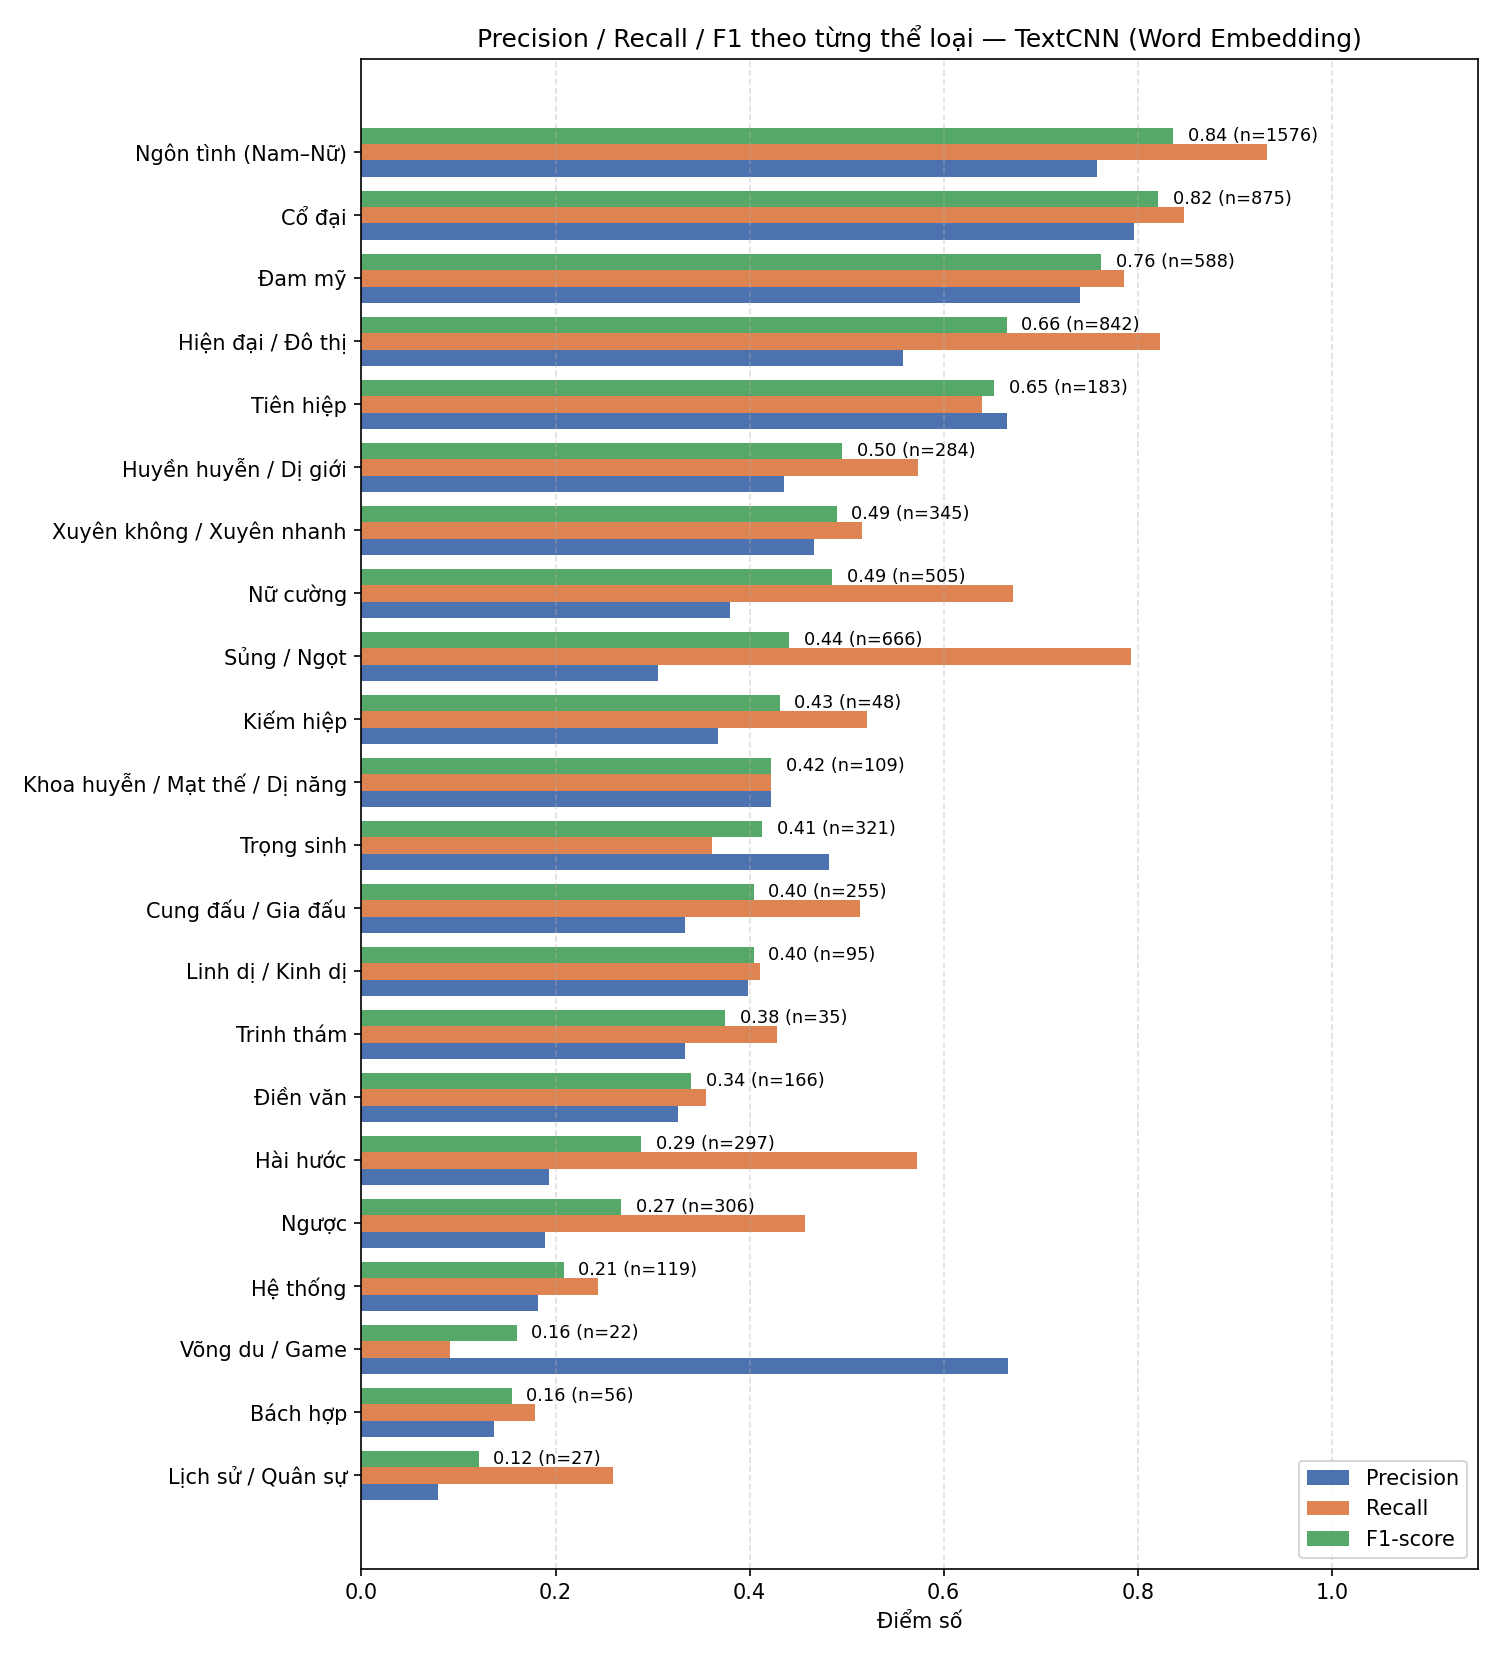

In [4]:
# Vẽ và lưu 3 biểu đồ chuẩn vào outputs/figures/
from IPython.display import Image, display

fig_lc = plot_dl_learning_curves(
    {"TextCNN (PPMI-SVD)": cnn_history},
    output_path=FIGURES_DIR / "dl_learning_curves.png",
)
fig_all = plot_model_comparison(
    all_exp_df,
    output_path=FIGURES_DIR / "all_models_comparison.png",
)
fig_dl_f1 = plot_f1_per_label(
    te_metrics["per_label"],
    label_names=GENRE_LABELS,
    model_name="TextCNN (Word Embedding)",
    output_path=FIGURES_DIR / "dl_f1_per_label.png",
)

for p in [fig_lc, fig_all, fig_dl_f1]:
    if p is not None and p.exists():
        print("Đã lưu biểu đồ:", p)
        display(Image(filename=str(p)))

### Biểu đồ trực quan Learning Curves, So sánh 5 thí nghiệm & F1 theo 22 nhãn
- Xuất 3 biểu đồ chuẩn: `dl_learning_curves.png`, `all_models_comparison.png`, `dl_f1_per_label.png`.

In [5]:
# Kiểm định độ tin cậy thống kê (Bootstrap 95% CI, 1.000 lần): Logistic Regression vs Linear SVM vs TextCNN
from sklearn.metrics import f1_score
from src.config import TABLES_DIR, TFIDF_VECTORIZER_PATH
from src.features.bow_tfidf import load_tfidf_vectorizer
from src.models.ml_models import apply_thresholds, load_model, predict_probabilities
from src.models.textcnn import load_textcnn_checkpoint, predict_torch_probs

exp_df = pd.read_csv(EXPERIMENTS_CSV, encoding="utf-8")
tfidf_vec = load_tfidf_vectorizer(TFIDF_VECTORIZER_PATH)
x_test_tfidf = tfidf_vec.transform(test_tokens)

ml_thresh_map = json.loads((MODELS_DIR / "ml_thresholds.json").read_text(encoding="utf-8"))
dl_thresh_map = json.loads((MODELS_DIR / "dl_thresholds.json").read_text(encoding="utf-8"))

logreg_model = load_model("logistic_regression", MODELS_DIR)
svm_model = load_model("linear_svm", MODELS_DIR)
textcnn_eval_bundle = load_textcnn_checkpoint(MODELS_DIR / "textcnn.pt", device="cpu")
textcnn_eval_model = textcnn_eval_bundle["model"]
x_seq_val_eval = texts_to_sequences(val_tokens, textcnn_eval_bundle["vocab"], max_len=textcnn_eval_bundle["max_len"])
x_seq_test_eval = texts_to_sequences(test_tokens, textcnn_eval_bundle["vocab"], max_len=textcnn_eval_bundle["max_len"])

logreg_thresh = np.array([ml_thresh_map["logistic_regression"][g] for g in GENRE_LABELS], dtype=np.float32)
svm_thresh = np.array([ml_thresh_map["linear_svm"][g] for g in GENRE_LABELS], dtype=np.float32)
textcnn_thresh = np.array([dl_thresh_map["TN5_textcnn"][g] for g in GENRE_LABELS], dtype=np.float32)

probs_dict = {
    "Logistic Regression": predict_probabilities(logreg_model, x_test_tfidf),
    "Linear SVM": predict_probabilities(svm_model, x_test_tfidf),
    "TextCNN (Word Embedding)": predict_torch_probs(
        textcnn_eval_model,
        DataLoader(TensorDataset(torch.tensor(x_seq_test_eval, dtype=torch.long)), batch_size=256),
    ),
}
preds_dict = {
    "Logistic Regression": apply_thresholds(probs_dict["Logistic Regression"], logreg_thresh),
    "Linear SVM": apply_thresholds(probs_dict["Linear SVM"], svm_thresh),
    "TextCNN (Word Embedding)": apply_thresholds(probs_dict["TextCNN (Word Embedding)"], textcnn_thresh),
}

y_val_int = y_val.astype(int)
y_test_int = y_test.astype(int)

rng = np.random.default_rng(RANDOM_STATE)
n_boot = 1000
n_test = len(y_test_int)
boot_idx = rng.integers(0, n_test, size=(n_boot, n_test))

boot_rows = []
boot_samples = {}
for name, y_pred in preds_dict.items():
    macros = np.empty(n_boot, dtype=np.float64)
    micros = np.empty(n_boot, dtype=np.float64)
    for b in range(n_boot):
        idx = boot_idx[b]
        macros[b] = f1_score(y_test_int[idx], y_pred[idx], average="macro", zero_division=0)
        micros[b] = f1_score(y_test_int[idx], y_pred[idx], average="micro", zero_division=0)
    boot_samples[name] = {"macro": macros, "micro": micros}
    point = evaluate_model(y_test_int, y_pred, GENRE_LABELS)
    boot_rows.append(
        {
            "model": name,
            "macro_f1": point["macro_f1"],
            "macro_ci_95": f"[{np.percentile(macros, 2.5):.4f}, {np.percentile(macros, 97.5):.4f}]",
            "micro_f1": point["micro_f1"],
            "micro_ci_95": f"[{np.percentile(micros, 2.5):.4f}, {np.percentile(micros, 97.5):.4f}]",
            "hamming_loss": point["hamming_loss"],
        }
    )

diff_lr_svm = boot_samples["Logistic Regression"]["macro"] - boot_samples["Linear SVM"]["macro"]
diff_lr_cnn = boot_samples["Logistic Regression"]["macro"] - boot_samples["TextCNN (Word Embedding)"]["macro"]
print(f"Chênh lệch Macro-F1 (LogReg - SVM) 95% CI: [{np.percentile(diff_lr_svm, 2.5):+.4f}, {np.percentile(diff_lr_svm, 97.5):+.4f}]")
print(f"Chênh lệch Macro-F1 (LogReg - TextCNN) 95% CI: [{np.percentile(diff_lr_cnn, 2.5):+.4f}, {np.percentile(diff_lr_cnn, 97.5):+.4f}]")
display(exp_df)
display(pd.DataFrame(boot_rows))

Chênh lệch Macro-F1 (LogReg - SVM) 95% CI: [+0.0022, +0.0237]
Chênh lệch Macro-F1 (LogReg - TextCNN) 95% CI: [+0.0312, +0.0714]


,experiment_id,model_name,feature_type,accuracy,macro_f1,micro_f1,hamming_loss,notes
0,TN1_nb_bow,Multinomial NB (BoW),BoW (1-2 gram),0.0603,0.4319,0.5641,0.1300,Test set (2672 mẫu) | alpha=0.1 | tuned_thresh...
1,TN2_multinomial_nb,Multinomial NB (TF-IDF),TF-IDF (1-2 gram),0.0584,0.4031,0.5877,0.1207,Test set (2672 mẫu) | alpha=0.05 | tuned_thres...
2,TN3_linear_svm,Linear SVM (TF-IDF),TF-IDF (1-2 gram),0.0618,0.4767,0.6006,0.1193,"Test set (2672 mẫu) | C=0.25, cw=balanced | tu..."
3,TN4_logistic_regression,Logistic Regression (TF-IDF),TF-IDF (1-2 gram),0.0561,0.4897,0.6035,0.1230,"Test set (2672 mẫu) | C=1.0, cw=balanced | tun..."
4,TN5_textcnn,TextCNN (Word Embedding),PPMI-SVD Emb + Multi-scale CNN (max_len=200),0.0423,0.4381,0.5742,0.1383,"Test set (2672 mẫu) | TextCNN (k=2,3,4; f=64; ..."


,model,macro_f1,macro_ci_95,micro_f1,micro_ci_95,hamming_loss
0,Logistic Regression,0.4897,"[0.4681, 0.5065]",0.6035,"[0.5950, 0.6121]",0.1230
1,Linear SVM,0.4767,"[0.4571, 0.4938]",0.6006,"[0.5921, 0.6089]",0.1193
2,TextCNN (Word Embedding),0.4381,"[0.4221, 0.4537]",0.5742,"[0.5659, 0.5829]",0.1383


### Phân tích độ tin cậy thống kê (Bootstrap 95% CI)
- `Logistic Regression`: `Macro-F1 = 0.4897 [0.4681, 0.5065]`, `Micro-F1 = 0.6035 [0.5950, 0.6121]`.
- `Linear SVM`: `Macro-F1 = 0.4767 [0.4571, 0.4938]`, `Micro-F1 = 0.6006 [0.5921, 0.6089]`.
- `TextCNN (Word Embedding)`: `Macro-F1 = 0.4381 [0.4221, 0.4537]`, `Micro-F1 = 0.5742 [0.5659, 0.5829]`.
- Khoảng tin cậy 95% hiệu số `LogReg - SVM` (`[+0.0022, +0.0237]`) và `LogReg - TextCNN` (`[+0.0312, +0.0714]`) đều nằm hoàn toàn bên dương, chứng minh `Logistic Regression` dẫn đầu có ý nghĩa thống kê.

Đã lưu bảng phân tích theo phân khúc tại: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\tables\error_analysis_by_slice.csv


,dimension,slice,n_samples,avg_labels,logreg_micro_f1,logreg_macro_f1,logreg_exact_acc,svm_micro_f1,svm_macro_f1,svm_exact_acc,textcnn_micro_f1,textcnn_macro_f1,textcnn_exact_acc
0,header_bucket,Có header Thể loại,685,2.74,0.6026,0.4561,0.0832,0.5999,0.4419,0.0818,0.5649,0.3960,0.0482
1,header_bucket,Không có header,1987,2.94,0.6038,0.4843,0.0468,0.6008,0.4753,0.0549,0.5772,0.4488,0.0403
2,length_bucket,<100 từ,597,2.66,0.5703,0.4182,0.0402,0.5590,0.4002,0.0519,0.5447,0.3922,0.0469
3,length_bucket,100-250 từ,1393,2.92,0.6052,0.4872,0.0452,0.6025,0.4770,0.0495,0.5809,0.4428,0.0337
4,length_bucket,>250 từ,682,3.03,0.6262,0.5105,0.0924,0.6288,0.4987,0.0953,0.5826,0.4385,0.0557
5,n_labels_bucket,1 nhãn,539,1.00,0.3389,0.2050,0.0130,0.3639,0.1898,0.0241,0.3134,0.1893,0.0056
6,n_labels_bucket,2 nhãn,587,2.00,0.5775,0.4484,0.0630,0.5766,0.4280,0.0681,0.5283,0.3687,0.0460
7,n_labels_bucket,3 nhãn,717,3.00,0.6668,0.4840,0.0921,0.6637,0.4789,0.1088,0.6253,0.4195,0.0725
8,n_labels_bucket,>=4 nhãn,829,4.65,0.6572,0.4972,0.0483,0.6420,0.4840,0.0410,0.6433,0.4623,0.0374


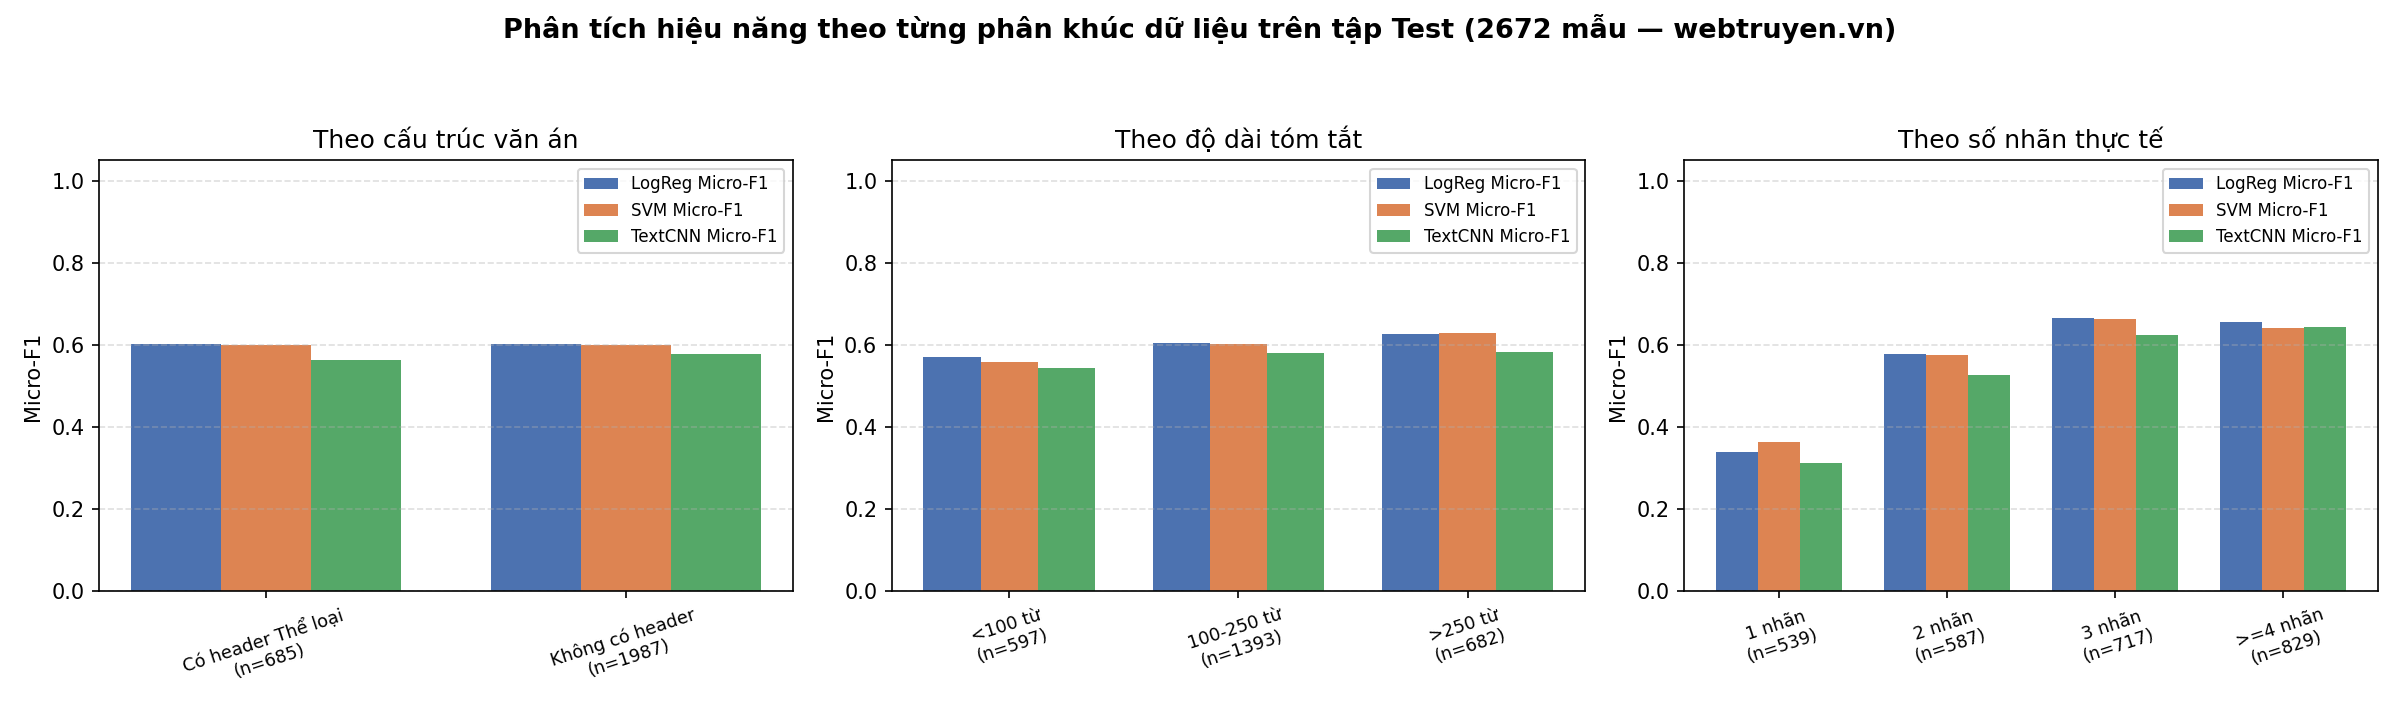

In [6]:
# Slice-based Error Analysis theo cấu trúc văn án, độ dài tóm tắt và số nhãn thực tế
import matplotlib.pyplot as plt

test_eval = test_df.copy()
test_eval["length_bucket"] = pd.cut(
    test_eval["n_words"],
    bins=[0, 100, 250, 100000],
    labels=["<100 từ", "100-250 từ", ">250 từ"],
)
test_eval["header_bucket"] = test_eval["summary"].fillna("").str.contains(
    r"thể\s*loại\s*[:\-]", case=False, regex=True
).map({True: "Có header Thể loại", False: "Không có header"})
test_eval["n_labels_bucket"] = test_eval["n_labels"].apply(lambda k: ">=4 nhãn" if k >= 4 else f"{int(k)} nhãn")

def _slice_metrics(group_col: str, ordered_keys=None) -> pd.DataFrame:
    rows = []
    keys = ordered_keys if ordered_keys is not None else sorted(test_eval[group_col].astype(str).unique())
    for key in keys:
        mask = (test_eval[group_col].astype(str) == key).to_numpy()
        if mask.sum() == 0:
            continue
        yt = y_test_int[mask]
        row = {"dimension": group_col, "slice": key, "n_samples": int(mask.sum()), "avg_labels": round(float(yt.sum(axis=1).mean()), 2)}
        for m_key, m_col in [("Logistic Regression", "logreg"), ("Linear SVM", "svm"), ("TextCNN (Word Embedding)", "textcnn")]:
            yp = preds_dict[m_key][mask]
            present = (yt.sum(axis=0) + yp.sum(axis=0)) > 0
            macro_present = float(f1_score(yt[:, present], yp[:, present], average="macro", zero_division=0)) if present.any() else 0.0
            micro = float(f1_score(yt, yp, average="micro", zero_division=0))
            acc = float((yt == yp).all(axis=1).mean())
            row[f"{m_col}_micro_f1"] = round(micro, 4)
            row[f"{m_col}_macro_f1"] = round(macro_present, 4)
            row[f"{m_col}_exact_acc"] = round(acc, 4)
        rows.append(row)
    return pd.DataFrame(rows)

slice_df = pd.concat([
    _slice_metrics("header_bucket", ["Có header Thể loại", "Không có header"]),
    _slice_metrics("length_bucket", ["<100 từ", "100-250 từ", ">250 từ"]),
    _slice_metrics("n_labels_bucket", ["1 nhãn", "2 nhãn", "3 nhãn", ">=4 nhãn"]),
], ignore_index=True)

slice_csv_path = TABLES_DIR / "error_analysis_by_slice.csv"
slice_df.to_csv(slice_csv_path, index=False, encoding="utf-8")
print(f"Đã lưu bảng phân tích theo phân khúc tại: {slice_csv_path}")
display(slice_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
dims = [("header_bucket", "Theo cấu trúc văn án"), ("length_bucket", "Theo độ dài tóm tắt"), ("n_labels_bucket", "Theo số nhãn thực tế")]
for ax, (dim_name, title) in zip(axes, dims):
    sub = slice_df[slice_df["dimension"] == dim_name]
    x = np.arange(len(sub))
    w = 0.25
    ax.bar(x - w, sub["logreg_micro_f1"], width=w, label="LogReg Micro-F1", color="#4c72b0")
    ax.bar(x, sub["svm_micro_f1"], width=w, label="SVM Micro-F1", color="#dd8452")
    ax.bar(x + w, sub["textcnn_micro_f1"], width=w, label="TextCNN Micro-F1", color="#55a868")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{s}\n(n={n})" for s, n in zip(sub["slice"], sub["n_samples"])], rotation=18, fontsize=8.5)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Micro-F1")
    ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(fontsize=8)

fig.suptitle(f"Phân tích hiệu năng theo từng phân khúc dữ liệu trên tập Test ({len(y_test_int)} mẫu — webtruyen.vn)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
slice_fig_path = FIGURES_DIR / "error_analysis_slices.png"
plt.savefig(slice_fig_path, dpi=150)
plt.close(fig)
display(Image(filename=str(slice_fig_path)))

### Phân tích lỗi theo phân khúc dữ liệu (`2.672` mẫu Test)
- Văn án dài `>250` từ (`n=682`) đạt hiệu năng cao nhất trên cả 3 mô hình (`LogReg Micro-F1 = 0.6262 / Macro-F1 = 0.5105`, `SVM = 0.6288 / 0.4987`, `TextCNN = 0.5826 / 0.4385`), vượt nhóm `<100` từ (`n=597`, `Micro-F1 = 0.5447–0.5703`).
- Truyện `3 nhãn` (`n=717`) đạt `LogReg Micro-F1 = 0.6668` (`SVM Exact Acc = 10.88%`, `TextCNN Micro-F1 = 0.6253`), còn truyện `>=4 nhãn` (`n=829`, `avg_labels = 4.65`) đạt `LogReg Macro-F1 = 0.4972` (`Micro-F1 = 0.6572`, `TextCNN Micro-F1 = 0.6433`).

In [7]:
# Phân nhóm lỗi thừa/thiếu nhãn giữa 3 mô hình & Khảo sát độ nhạy ngưỡng trên nhãn trong_sinh của TextCNN
err_type_rows = []
for name, y_pred in preds_dict.items():
    exact = int(((y_test_int == y_pred).all(axis=1)).sum())
    fp_cnt = ((y_pred == 1) & (y_test_int == 0)).sum(axis=1)
    fn_cnt = ((y_pred == 0) & (y_test_int == 1)).sum(axis=1)
    overlap = ((y_pred == 1) & (y_test_int == 1)).sum(axis=1)

    zero_overlap = int((overlap == 0).sum())
    fn_only = int(((fn_cnt > 0) & (fp_cnt == 0) & (overlap > 0)).sum())
    fp_only = int(((fp_cnt > 0) & (fn_cnt == 0) & (overlap > 0)).sum())
    both = int(((fp_cnt > 0) & (fn_cnt > 0) & (overlap > 0)).sum())

    err_type_rows.append(
        {
            "model": name,
            "exact_match": f"{exact} ({exact/len(y_test_int)*100:.1f}%)",
            "fn_only_thieu_nhan": f"{fn_only} ({fn_only/len(y_test_int)*100:.1f}%)",
            "fp_only_thua_nhan": f"{fp_only} ({fp_only/len(y_test_int)*100:.1f}%)",
            "both_fp_fn": f"{both} ({both/len(y_test_int)*100:.1f}%)",
            "zero_overlap_sai_hoan_toan": f"{zero_overlap} ({zero_overlap/len(y_test_int)*100:.1f}%)",
            "avg_pred_labels": round(float(y_pred.sum(axis=1).mean()), 2),
        }
    )

print(f"Số nhãn trung bình thực tế trên tập test: {y_test_int.sum(axis=1).mean():.2f}")
display(pd.DataFrame(err_type_rows))

ts_idx = GENRE_LABELS.index("trong_sinh")
textcnn_val_probs = predict_torch_probs(
    textcnn_eval_model,
    DataLoader(TensorDataset(torch.tensor(x_seq_val_eval, dtype=torch.long)), batch_size=256),
)
textcnn_test_probs = probs_dict["TextCNN (Word Embedding)"]
sens_rows = []
for t in [0.30, 0.35, 0.40, 0.45, 0.50, 0.60]:
    vp = (textcnn_val_probs[:, ts_idx] >= t).astype(int)
    tp = (textcnn_test_probs[:, ts_idx] >= t).astype(int)
    sens_rows.append(
        {
            "threshold": t,
            "val_f1": round(float(f1_score(y_val_int[:, ts_idx], vp, zero_division=0)), 4),
            "test_precision": round(float(((tp == 1) & (y_test_int[:, ts_idx] == 1)).sum() / max(1, tp.sum())), 4),
            "test_recall": round(float(((tp == 1) & (y_test_int[:, ts_idx] == 1)).sum() / max(1, y_test_int[:, ts_idx].sum())), 4),
            "test_f1": round(float(f1_score(y_test_int[:, ts_idx], tp, zero_division=0)), 4),
        }
    )
print("\nĐộ nhạy ngưỡng trên nhãn trong_sinh của TextCNN (Word Embedding):")
display(pd.DataFrame(sens_rows))

Số nhãn trung bình thực tế trên tập test: 2.89


,model,exact_match,fn_only_thieu_nhan,fp_only_thua_nhan,both_fp_fn,zero_overlap_sai_hoan_toan,avg_pred_labels
0,Logistic Regression,150 (5.6%),216 (8.1%),1138 (42.6%),991 (37.1%),177 (6.6%),3.94
1,Linear SVM,165 (6.2%),277 (10.4%),1015 (38.0%),1028 (38.5%),187 (7.0%),3.68
2,TextCNN (Word Embedding),113 (4.2%),225 (8.4%),1137 (42.6%),985 (36.9%),212 (7.9%),4.26



Độ nhạy ngưỡng trên nhãn trong_sinh của TextCNN (Word Embedding):


,threshold,val_f1,test_precision,test_recall,test_f1
0,0.30,0.4195,0.3117,0.5981,0.4098
1,0.35,0.4447,0.3333,0.5607,0.4181
2,0.40,0.4444,0.3658,0.5265,0.4317
3,0.45,0.4593,0.3980,0.4984,0.4426
4,0.50,0.4688,0.4354,0.4517,0.4434
5,0.60,0.4867,0.4715,0.3614,0.4092


### Phân tích lỗi thừa/thiếu nhãn & Độ nhạy ngưỡng `TextCNN`
- Số nhãn TB thực tế trên `test` là `2.89`; các mô hình dự đoán TB `3.94` (`LogReg`), `3.68` (`SVM`), `4.26` (`TextCNN`). `Linear SVM` đạt `Exact Match = 165 (6.2%)`, `LogReg` đạt `150 (5.6%)`, `TextCNN` đạt `113 (4.2%)`.
- Kiểm tra độ nhạy ngưỡng nhãn `trong_sinh` của `TextCNN`: ngưỡng `0.50` đạt `val_f1 = 0.4688` và `test_f1 = 0.4434` (`Precision = 0.4354`, `Recall = 0.4517`); khi tăng lên `0.60`, `val_f1` tăng lên `0.4867` nhưng trên `test` độ phủ giảm xuống `Recall = 0.3614` (`Precision = 0.4715`, `test_f1 = 0.4092`).

## Tổng kết Giai đoạn 5b (TextCNN & So sánh toàn hệ thống)
- **`TextCNN (Word Embedding)`** đạt `Macro-F1 = 0.4381`, `Micro-F1 = 0.5742`, `Hamming Loss = 0.1383` sau `10 epochs` (`284.83s`).
- Đối chiếu 5 thí nghiệm bằng Bootstrap 95% CI khẳng định **`Logistic Regression (TF-IDF)`** dẫn đầu có ý nghĩa thống kê (`Macro-F1 = 0.4897`, `Micro-F1 = 0.6035`), đi kèm **`Linear SVM`** (`Macro-F1 = 0.4767`, `Exact Match = 6.2%`) và **`TextCNN`** trong ứng dụng Streamlit (`app/streamlit_app.py`).